In [114]:
import os
os.environ["HF_HOME"] = "C:/huggingface_cache"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

from datasets import load_dataset
import pandas as pd

print("Loading Polyvore...")
ds_poly = load_dataset("Marqo/polyvore", split="data")
df_poly = ds_poly.remove_columns(["image"]).to_pandas()

print(f"Total rows: {len(df_poly)}")
print(f"Columns: {df_poly.columns.tolist()}")
print(f"\nSample rows:")
print(df_poly.head(10))

# Extract outfit ID and position
df_poly["outfit_id"] = df_poly["item_ID"].str.rsplit("_", n=1).str[0]
df_poly["position"]  = df_poly["item_ID"].str.rsplit("_", n=1).str[1]

print(f"\nUnique outfits: {df_poly['outfit_id'].nunique()}")
print(f"Unique items: {df_poly['item_ID'].nunique()}")
print(f"\nTop categories:")
print(df_poly["category"].value_counts().head(20))

Loading Polyvore...
Total rows: 94096
Columns: ['category', 'text', 'item_ID']

Sample rows:
       category                                           text      item_ID
0   Day Dresses                    tibi knit long sleeve dress  100002074_1
1         Boots       michael kors leather over-the-knee boots  100002074_2
2      Handbags  givenchy leather medium antigona duffel black  100002074_3
3    Sunglasses      bottega veneta acetate leather sunglasses  100002074_4
4  Floral Decor                              pier imports stem  100002074_5
5         Coats                                   miranda coat  100002074_7
6       Blazers                            three pocket blazer  100010727_1
7  Skinny Jeans                           givenchy skinny jean  100010727_2
8       Watches      guess black silver-tone chronograph watch  100010727_4
9    Sunglasses           ray-ban original wayfarer sunglasses  100010727_5

Unique outfits: 21587
Unique items: 94096

Top categories:
category
Ea

In [115]:
#for updating feedback using features
import json
import os

# ── Feedback log storage (replaces the old liked/disliked ID lists) ────
FEEDBACK_LOG_FILE = "feedback_log.json"

def load_feedback_log():
    if os.path.exists(FEEDBACK_LOG_FILE):
        with open(FEEDBACK_LOG_FILE) as f:
            return json.load(f)
    return []  # flat list of {"features": {...}, "label": 0/1} records

def save_feedback_log(log):
    with open(FEEDBACK_LOG_FILE, "w") as f:
        json.dump(log, f)

In [116]:
#old feedback storage (liked/disliked ID lists)
# FEEDBACK_FILE = "user_feedback.json"

# def load_feedback():
#     if os.path.exists(FEEDBACK_FILE):
#         with open(FEEDBACK_FILE) as f:
#             return json.load(f)
#     return {"liked": [], "disliked": []}

# def save_feedback(feedback):
#     with open(FEEDBACK_FILE, "w") as f:
#         json.dump(feedback, f)

# feedback_store = load_feedback()

In [117]:
# Define which Polyvore categories are tops and bottoms
TOP_CATEGORIES = [
    "Tops", "T-Shirts", "Blouses", "Sweaters", "Sweatshirts",
    "Tank Tops", "Men's Shirts", "Blazers", "Jackets", "Coats",
    "Vests", "Intimates"
]

BOTTOM_CATEGORIES = [
    "Skinny Jeans", "Boyfriend Jeans", "Shorts", "Skirts",
    "Pants", "Leggings", "Joggers", "Trousers", "Jeans",
    "Day Dresses", "Rompers"
]

df_poly["garment_type"] = None
df_poly.loc[df_poly["category"].isin(TOP_CATEGORIES), "garment_type"]    = "top"
df_poly.loc[df_poly["category"].isin(BOTTOM_CATEGORIES), "garment_type"] = "bottom"

# Keep only tops and bottoms
df_poly_filtered = df_poly[df_poly["garment_type"].notna()].copy()

print(f"After filtering: {len(df_poly_filtered)} items")
print(df_poly_filtered["garment_type"].value_counts())
print(f"\nUnique outfits with tops/bottoms: {df_poly_filtered['outfit_id'].nunique()}")

After filtering: 22662 items
garment_type
top       14543
bottom     8119
Name: count, dtype: int64

Unique outfits with tops/bottoms: 14988


In [118]:
import random
random.seed(42)

pairs = []
seen  = set()

# Group by outfit
outfit_groups = df_poly_filtered.groupby("outfit_id")

# Positive pairs — top + bottom from SAME outfit
for outfit_id, group in outfit_groups:
    tops    = group[group["garment_type"] == "top"]["item_ID"].tolist()
    bottoms = group[group["garment_type"] == "bottom"]["item_ID"].tolist()
    
    if len(tops) == 0 or len(bottoms) == 0:
        continue
    
    for top in tops:
        for bottom in bottoms:
            pair_id = (top, bottom)
            if pair_id in seen:
                continue
            seen.add(pair_id)
            pairs.append({
                "item_A": top,
                "item_B": bottom,
                "label":  1   # REAL compatible pair
            })

print(f"Positive pairs created: {len(pairs)}")

# Negative pairs — top from one outfit + bottom from DIFFERENT outfit
all_tops    = df_poly_filtered[df_poly_filtered["garment_type"] == "top"]["item_ID"].tolist()
all_bottoms = df_poly_filtered[df_poly_filtered["garment_type"] == "bottom"]["item_ID"].tolist()

# Build outfit lookup for fast checking
item_to_outfit = dict(zip(df_poly_filtered["item_ID"], df_poly_filtered["outfit_id"]))

neg_count    = 0
neg_attempts = 0
target_negs  = len(pairs)  # equal positive and negative

while neg_count < target_negs:
    neg_attempts += 1
    if neg_attempts > target_negs * 20:
        print(f"Could only make {neg_count} negative pairs")
        break
    
    top    = random.choice(all_tops)
    bottom = random.choice(all_bottoms)
    
    # Make sure they're from DIFFERENT outfits
    if item_to_outfit[top] == item_to_outfit[bottom]:
        continue
    
    pair_id = (top, bottom)
    if pair_id in seen:
        continue
    
    seen.add(pair_id)
    pairs.append({
        "item_A": top,
        "item_B": bottom,
        "label":  0   # REAL incompatible pair
    })
    neg_count += 1

pairs_df_poly = pd.DataFrame(pairs)
print(f"\nTotal pairs: {len(pairs_df_poly)}")
print(f"Positive: {len(pairs_df_poly[pairs_df_poly['label'] == 1])}")
print(f"Negative: {len(pairs_df_poly[pairs_df_poly['label'] == 0])}")

Positive pairs created: 5969

Total pairs: 11938
Positive: 5969
Negative: 5969


In [119]:
import open_clip
import torch
from PIL import Image
import io
import numpy as np

# Load FashionCLIP
print("Loading FashionCLIP...")
clip_model, _, preprocess = open_clip.create_model_and_transforms(
    'hf-hub:Marqo/marqo-fashionSigLIP'
)
clip_model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
clip_model = clip_model.to(device)
print(f"FashionCLIP loaded on {device}")

Loading FashionCLIP...
FashionCLIP loaded on cpu


In [120]:
#----------------FEATURE EXTRACTION(not needed anymore already extracted features and saved in feature_dict_polyvore.npy)------------------------
# Get unique item IDs needed
# unique_ids_needed = set(
#     pairs_df_poly["item_A"].tolist() + 
#     pairs_df_poly["item_B"].tolist()
# )
# print(f"Unique items needed: {len(unique_ids_needed)}")

# # Filter dataset to only needed items
# ds_poly_filtered = ds_poly.filter(
#     lambda row: row["item_ID"] in unique_ids_needed
# )
# print(f"Items to extract: {len(ds_poly_filtered)}")

# # Extract features
# feature_dict_poly = {}
# batch_size = 32
# failed = 0

# for start in range(0, len(ds_poly_filtered), batch_size):
#     batch        = ds_poly_filtered[start : start + batch_size]
#     batch_tensors = []
#     batch_ids     = []
    
#     for i in range(len(batch["item_ID"])):
#         try:
#             img    = batch["image"][i]
#             if img.mode != "RGB":
#                 img = img.convert("RGB")
#             tensor = preprocess(img)
#             batch_tensors.append(tensor)
#             batch_ids.append(batch["item_ID"][i])
#         except:
#             failed += 1
#             continue
    
#     if len(batch_tensors) == 0:
#         continue
    
#     batch_tensor = torch.stack(batch_tensors).to(device)
    
#     with torch.no_grad():
#         features = clip_model.encode_image(batch_tensor)
#         features = features / features.norm(dim=-1, keepdim=True)  # normalize
    
#     for i, item_id in enumerate(batch_ids):
#         feature_dict_poly[item_id] = features[i].cpu().numpy()
    
#     if (start // batch_size) % 50 == 0:
#         print(f"Extracted {len(feature_dict_poly)}/{len(ds_poly_filtered)} | Failed: {failed}")

# np.save("D:/feature_dict_polyvore.npy", feature_dict_poly)
# print(f"Done! Extracted: {len(feature_dict_poly)} | Failed: {failed}")

In [121]:
feature_dict_poly = np.load("C:/Users/shriy/Documents/feature_dict_polyvore.npy", allow_pickle=True).item()
print("Total extracted features:", len(feature_dict_poly))

sample_id = list(feature_dict_poly.keys())[0]
sample_vec = feature_dict_poly[sample_id]

print("Sample ID:", sample_id)
print("Vector shape:", sample_vec.shape)
print("Vector dtype:", sample_vec.dtype)

Total extracted features: 15264
Sample ID: 100002074_1
Vector shape: (768,)
Vector dtype: float32


In [122]:
pairs_df_poly["item_A"] = pairs_df_poly["item_A"].astype(str)
pairs_df_poly["item_B"] = pairs_df_poly["item_B"].astype(str)

pairs_df_poly["vec_A"] = pairs_df_poly["item_A"].map(feature_dict_poly)
pairs_df_poly["vec_B"] = pairs_df_poly["item_B"].map(feature_dict_poly)

print("Before drop:", len(pairs_df_poly))
print("Missing vec_A:", pairs_df_poly["vec_A"].isna().sum())
print("Missing vec_B:", pairs_df_poly["vec_B"].isna().sum())

pairs_df_poly = pairs_df_poly.dropna(subset=["vec_A", "vec_B"]).copy()

print("After drop:", len(pairs_df_poly))

Before drop: 11938
Missing vec_A: 0
Missing vec_B: 0
After drop: 11938


In [123]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# ── Dataset ──────────────────────────────────────────────────────────────
class PairDataset(Dataset):
    def __init__(self, df):
        self.vec_A  = np.stack(df["vec_A"].values)
        self.vec_B  = np.stack(df["vec_B"].values)
        self.labels = df["label"].values.astype(np.float32)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.vec_A[idx], dtype=torch.float32),
            torch.tensor(self.vec_B[idx], dtype=torch.float32),
            torch.tensor(self.labels[idx], dtype=torch.float32)
        )

# ── Siamese Network ───────────────────────────────────────────────────────
class SiameseNet(nn.Module):
    def __init__(self, input_dim=768):
        super().__init__()
        self.branch = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.classifier = nn.Sequential(
            nn.Linear(256, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )
        # Kaiming init
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                nn.init.zeros_(m.bias)

    def forward(self, a, b):
        emb_a = self.branch(a)
        emb_b = self.branch(b)
        combined = torch.cat([torch.abs(emb_a - emb_b), emb_a * emb_b], dim=1)  # 256-dim
        return self.classifier(combined).squeeze(1)

# ── Train / Val split ─────────────────────────────────────────────────────
train_df, val_df = train_test_split(pairs_df_poly, test_size=0.15, random_state=42, stratify=pairs_df_poly["label"])
print(f"Train: {len(train_df)} | Val: {len(val_df)}")

train_ds = PairDataset(train_df)
val_ds   = PairDataset(val_df)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=0)

# ── Model, loss, optimizer ────────────────────────────────────────────────
model     = SiameseNet(input_dim=768).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=4, factor=0.5)

# ── Training loop ─────────────────────────────────────────────────────────
best_val_loss   = float("inf")
early_stop_pat  = 8
no_improve      = 0
EPOCHS          = 50

for epoch in range(1, EPOCHS + 1):
    # --- train ---
    model.train()
    train_loss, train_correct, train_total = 0, 0, 0
    for a, b, label in train_loader:
        a, b, label = a.to(device), b.to(device), label.to(device)
        optimizer.zero_grad()
        logits = model(a, b)
        loss   = criterion(logits, label)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        train_loss    += loss.item() * len(label)
        preds          = (torch.sigmoid(logits) > 0.5).float()
        train_correct += (preds == label).sum().item()
        train_total   += len(label)

    # --- val ---
    model.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():
        for a, b, label in val_loader:
            a, b, label = a.to(device), b.to(device), label.to(device)
            logits = model(a, b)
            loss   = criterion(logits, label)
            val_loss    += loss.item() * len(label)
            preds        = (torch.sigmoid(logits) > 0.5).float()
            val_correct += (preds == label).sum().item()
            val_total   += len(label)

    avg_train_loss = train_loss / train_total
    avg_val_loss   = val_loss   / val_total
    train_acc      = train_correct / train_total
    val_acc        = val_correct   / val_total

    scheduler.step(avg_val_loss)
    print(f"Epoch {epoch:02d} | Train Loss: {avg_train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {avg_val_loss:.4f} Acc: {val_acc:.4f}")

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        no_improve    = 0
        torch.save(model.state_dict(), "C:/Users/shriy/Documents/best_model_polyvore.pth")
        print(f"  ✓ Saved best model (val_loss={best_val_loss:.4f})")
    else:
        no_improve += 1
        if no_improve >= early_stop_pat:
            print(f"Early stopping at epoch {epoch}")
            break

print(f"\nBest val loss: {best_val_loss:.4f}")

Train: 10147 | Val: 1791
Epoch 01 | Train Loss: 0.7292 Acc: 0.5384 | Val Loss: 0.6648 Acc: 0.5801
  ✓ Saved best model (val_loss=0.6648)
Epoch 02 | Train Loss: 0.6806 Acc: 0.5850 | Val Loss: 0.6492 Acc: 0.6170
  ✓ Saved best model (val_loss=0.6492)
Epoch 03 | Train Loss: 0.6487 Acc: 0.6112 | Val Loss: 0.6357 Acc: 0.6309
  ✓ Saved best model (val_loss=0.6357)
Epoch 04 | Train Loss: 0.6284 Acc: 0.6353 | Val Loss: 0.6236 Acc: 0.6438
  ✓ Saved best model (val_loss=0.6236)
Epoch 05 | Train Loss: 0.6066 Acc: 0.6590 | Val Loss: 0.6209 Acc: 0.6577
  ✓ Saved best model (val_loss=0.6209)
Epoch 06 | Train Loss: 0.5936 Acc: 0.6676 | Val Loss: 0.6104 Acc: 0.6639
  ✓ Saved best model (val_loss=0.6104)
Epoch 07 | Train Loss: 0.5868 Acc: 0.6821 | Val Loss: 0.6076 Acc: 0.6711
  ✓ Saved best model (val_loss=0.6076)
Epoch 08 | Train Loss: 0.5612 Acc: 0.7013 | Val Loss: 0.6128 Acc: 0.6795
Epoch 09 | Train Loss: 0.5436 Acc: 0.7155 | Val Loss: 0.6145 Acc: 0.6790
Epoch 10 | Train Loss: 0.5351 Acc: 0.7248 | V

In [124]:
from datasets import load_dataset
import torch
import numpy as np

import os

save_path = "C:/Users/shriy/Documents/feature_dict_f200k_clip.npy"

if os.path.exists(save_path):
    print("Loading cached features...")
    feature_dict_f200k = np.load(save_path, allow_pickle=True).item()
    print(f"Loaded {len(feature_dict_f200k)} features")

else:

# Load Fashion200K from HuggingFace
    print("Loading Fashion200K...")
    ds_f200k = load_dataset("Marqo/fashion200k", split="data")
    print(f"Total items: {len(ds_f200k)}")

# Load your subset CSV to know which item_IDs to keep
    import pandas as pd
    df_subset = pd.read_csv("D:/fashion200k_subset.csv")
    subset_ids = set(df_subset["item_ID"].astype(str).tolist())
    print(f"Subset items to extract: {len(subset_ids)}")

    # Filter HF dataset to only subset items
    ds_f200k_filtered = ds_f200k.filter(
        lambda row: str(row["item_ID"]) in subset_ids
    )
    print(f"Matched in HF dataset: {len(ds_f200k_filtered)}")

    # Extract FashionCLIP features
    feature_dict_f200k = {}
    batch_size = 32
    failed = 0

    for start in range(0, len(ds_f200k_filtered), batch_size):
        batch         = ds_f200k_filtered[start : start + batch_size]
        batch_tensors = []
        batch_ids     = []

        for i in range(len(batch["item_ID"])):
            try:
                img = batch["image"][i]
                if img.mode != "RGB":
                    img = img.convert("RGB")
                tensor = preprocess(img)
                batch_tensors.append(tensor)
                batch_ids.append(str(batch["item_ID"][i]))
            except:
                failed += 1
                continue

        if not batch_tensors:
            continue

        batch_tensor = torch.stack(batch_tensors).to(device)

        with torch.no_grad():
            features = clip_model.encode_image(batch_tensor)
            features = features / features.norm(dim=-1, keepdim=True)

        for i, item_id in enumerate(batch_ids):
            feature_dict_f200k[item_id] = features[i].cpu().numpy()

        if (start // batch_size) % 50 == 0:
            print(f"Extracted {len(feature_dict_f200k)}/{len(ds_f200k_filtered)} | Failed: {failed}")

    np.save("C:/Users/shriy/Documents/feature_dict_f200k_clip.npy", feature_dict_f200k)
    print(f"Done! Extracted: {len(feature_dict_f200k)} | Failed: {failed}")

Loading cached features...
Loaded 72333 features


In [125]:
from datasets import load_dataset
import pandas as pd
import numpy as np

# Reload HF dataset
print("Loading Fashion200K...")
ds_f200k = load_dataset("Marqo/fashion200k", split="data")

# Reload subset IDs
df_subset = pd.read_csv("C:/Users/shriy/Documents/fashion200k_subset.csv")
subset_ids = set(df_subset["item_ID"].astype(str).tolist())

# Filter (needed for id_to_index and image lookup later)
print("Filtering...")
ds_f200k_filtered = ds_f200k.filter(
    lambda row: str(row["item_ID"]) in subset_ids
)
print(f"Filtered: {len(ds_f200k_filtered)} items")

# Load already extracted features from disk — NO re-extraction
feature_dict_f200k = np.load("C:/Users/shriy/Documents/feature_dict_f200k_clip.npy", allow_pickle=True).item()
print(f"Features loaded: {len(feature_dict_f200k)} items")

Loading Fashion200K...
Filtering...
Filtered: 72363 items
Features loaded: 72333 items


In [126]:
print("Building ID to index lookup...")
id_to_index = {str(ds_f200k_filtered[i]["item_ID"]): i for i in range(len(ds_f200k_filtered))}
np.save("C:/Users/shriy/Documents/f200k_id_to_index.npy", id_to_index)
print(f"Done! {len(id_to_index)} items indexed")

Building ID to index lookup...
Done! 72333 items indexed


In [127]:
import faiss
import numpy as np
import pandas as pd

feature_dict_f200k = np.load("C:/Users/shriy/Documents/feature_dict_f200k_clip.npy", allow_pickle=True).item()
df_subset = pd.read_csv("C:/Users/shriy/Documents/fashion200k_subset.csv")
df_subset["item_ID"] = df_subset["item_ID"].astype(str)

print(f"Catalog size: {len(feature_dict_f200k)} items")

# Filter to only items we have features for
df_catalog = df_subset[df_subset["item_ID"].isin(feature_dict_f200k.keys())].copy()
print(f"Items with features: {len(df_catalog)}")
print(df_catalog["category1"].value_counts())

Catalog size: 72333 items
Items with features: 72333
category1
dresses    20974
tops       18237
pants      11921
skirts     10668
jackets    10533
Name: count, dtype: int64


In [128]:
TOP_CATS     = ["tops", "jackets"]
BOTTOM_CATS  = ["pants", "skirts"]
DRESS_CATS   = ["dresses"]

df_tops    = df_catalog[df_catalog["category1"].isin(TOP_CATS)].reset_index(drop=True)
df_bottoms = df_catalog[df_catalog["category1"].isin(BOTTOM_CATS)].reset_index(drop=True)
df_dresses = df_catalog[df_catalog["category1"].isin(DRESS_CATS)].reset_index(drop=True)

print(f"Tops: {len(df_tops)}")
print(f"Bottoms: {len(df_bottoms)}")
print(f"Dresses: {len(df_dresses)}")

# Build FAISS index for tops
top_vectors = np.stack([feature_dict_f200k[iid] for iid in df_tops["item_ID"]]).astype("float32")
index_tops  = faiss.IndexFlatIP(768)
index_tops.add(top_vectors)

# Build FAISS index for bottoms
bottom_vectors = np.stack([feature_dict_f200k[iid] for iid in df_bottoms["item_ID"]]).astype("float32")
index_bottoms  = faiss.IndexFlatIP(768)
index_bottoms.add(bottom_vectors)

# Build FAISS index for dresses
dress_vectors = np.stack([feature_dict_f200k[iid] for iid in df_dresses["item_ID"]]).astype("float32")
index_dresses = faiss.IndexFlatIP(768)
index_dresses.add(dress_vectors)

print(f"FAISS tops: {index_tops.ntotal}")
print(f"FAISS bottoms: {index_bottoms.ntotal}")
print(f"FAISS dresses: {index_dresses.ntotal}")

Tops: 28770
Bottoms: 22589
Dresses: 20974
FAISS tops: 28770
FAISS bottoms: 22589
FAISS dresses: 20974


In [129]:
import torch
import torch.nn as nn
import numpy as np
import faiss
import open_clip
import matplotlib.pyplot as plt
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load FashionCLIP
print("Loading FashionCLIP...")
clip_model, _, preprocess = open_clip.create_model_and_transforms(
    'hf-hub:Marqo/marqo-fashionSigLIP'
)
clip_model.eval().to(device)
tokenizer = open_clip.get_tokenizer('hf-hub:Marqo/marqo-fashionSigLIP')
print("FashionCLIP loaded")

# Load Siamese model
class SiameseNet(nn.Module):
    def __init__(self, input_dim=768):
        super().__init__()
        self.branch = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.4)
        )
        self.classifier = nn.Sequential(
            nn.Linear(256, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(64, 1)
        )
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                nn.init.zeros_(m.bias)

    def forward(self, a, b):
        emb_a = self.branch(a)
        emb_b = self.branch(b)
        combined = torch.cat([torch.abs(emb_a - emb_b), emb_a * emb_b], dim=1)
        return self.classifier(combined).squeeze(1)

model = SiameseNet(input_dim=768).to(device)
model.load_state_dict(torch.load("C:/Users/shriy/Documents/best_model_polyvore.pth", map_location=device))
model.eval()
print("Siamese model loaded")

Loading FashionCLIP...
FashionCLIP loaded
Siamese model loaded


In [130]:
# Diagnostic — check what your text fields look like
# print("=== BOTTOMS text samples ===")
# print(df_bottoms[["item_ID", "text", "category1", "category2"]].head(20))

# print("\n=== TOPS text samples ===")
# print(df_tops[["item_ID", "text", "category1", "category2"]].head(20))

In [131]:
def rate_recommendations(result):
    items = result["meta"]
    query_text = result.get("query_text", "")
    query_is_patterned = result.get("query_is_patterned", False)

    print("\nRate each recommendation (1=👍, 0=👎, s=skip). For 👎 you can type a reason (Enter to skip):")
    log = load_feedback_log()

    for i, row in items.iterrows():
        text = str(row.get("text", row.get("category1", "unknown")))
        rating = input(f"  Rec {i+1} ({text[:50]}): ").strip().lower()
        if rating not in ("1", "0"):
            print("    ⏭ Skipped")
            continue

        reason = input("    why? (optional): ").strip() if rating == "0" else ""
        feats = extract_feedback_features(
            query_text=query_text,
            query_is_patterned=query_is_patterned,
            candidate_row=row,
            clip_similarity=row.get("clip_similarity", 0.0),
            compat_score=row.get("compat_score_raw", 0.0),
        )
        log.append({
            "features":   feats,
            "label":      int(rating),
            "item_ID":    str(row["item_ID"]),
            "reason":     reason,
            "reason_vec": get_text_features(f"clothing that is {reason}").ravel().tolist() if reason else None,
        })
        print(f"    {'✅ liked' if rating == '1' else '❌ disliked'} saved")

    save_feedback_log(log)
    print(f"\nFeedback saved! {len(log)} labeled examples so far.")
    train_personalizer()      # auto-retrain (prints a message if not enough data yet)

In [132]:
# def apply_feedback_to_scores(candidate_meta, scores, feature_dict):
#     """
#     Boost liked items, penalize disliked ones based on vector similarity.
#     """
#     feedback = load_feedback()
    
#     if not feedback["liked"] and not feedback["disliked"]:
#         return scores  # no feedback yet, return as-is
    
#     adjusted_scores = scores.copy()
    
#     # Build average "liked" and "disliked" vectors
#     liked_vecs    = [feature_dict[iid] for iid in feedback["liked"]    if iid in feature_dict]
#     disliked_vecs = [feature_dict[iid] for iid in feedback["disliked"] if iid in feature_dict]
    
#     liked_center    = np.mean(liked_vecs,    axis=0) if liked_vecs    else None
#     disliked_center = np.mean(disliked_vecs, axis=0) if disliked_vecs else None
    
#     for i, row in candidate_meta.iterrows():
#         iid = row["item_ID"]
#         if iid not in feature_dict:
#             continue
#         vec = feature_dict[iid]
        
#         # Boost if similar to liked items
#         if liked_center is not None:
#             sim = np.dot(vec, liked_center)
#             adjusted_scores[i] += 0.3 * sim  # boost weight
        
#         # Penalize if similar to disliked items
#         if disliked_center is not None:
#             sim = np.dot(vec, disliked_center)
#             adjusted_scores[i] -= 0.5 * sim  # penalty weight
    
#     return adjusted_scores

In [133]:
# ── Style filter helpers ───────────────────────────────────────────────────
PATTERN_WORDS = ["floral", "print", "pattern", "stripe", "stripes", "striped",
                 "plaid", "check", "checkered", "polka", "dot", "graphic",
                 "animal", "leopard", "zebra", "tie-dye", "abstract", "geometric"]

CLASH_PAIRS = [
    {"red", "orange"}, {"red", "pink"}, {"red", "purple"},
    {"orange", "pink"}, {"orange", "purple"},
    {"yellow", "green"}, {"blue", "green"},
]

COLOR_WORDS = ["red", "orange", "yellow", "green", "blue", "purple",
               "pink", "white", "black", "grey", "gray", "brown", "navy"]

def is_patterned(text):
    t = str(text).lower()
    return any(w in t for w in PATTERN_WORDS)

def get_colors(text):
    t = str(text).lower()
    return {c for c in COLOR_WORDS if c in t}

def colors_clash(text_a, text_b):
    colors_a = get_colors(text_a)
    colors_b = get_colors(text_b)
    for pair in CLASH_PAIRS:
        if colors_a & pair and colors_b & pair:
            return True
    return False

# ── Image lookup ───────────────────────────────────────────────────────────
def get_item_image(item_id):
    idx = id_to_index[str(item_id)]
    return ds_f200k_filtered[idx]["image"]

# ── Core helpers ───────────────────────────────────────────────────────────
def detect_intent(text):
    text_lower = text.lower()
    if any(word in text_lower for word in ["dress", "gown", "frock"]):
        return "dress"
    elif any(word in text_lower for word in ["top", "shirt", "blouse", "sweater", "jacket"]):
        return "top"
    elif any(word in text_lower for word in ["bottom", "pants", "skirt", "jeans", "trousers"]):
        return "bottom"
    else:
        return "full_outfit"

def get_image_features(pil_image):
    if pil_image.mode != "RGB":
        pil_image = pil_image.convert("RGB")
    tensor = preprocess(pil_image).unsqueeze(0).to(device)
    with torch.no_grad():
        features = clip_model.encode_image(tensor)
        features = features / features.norm(dim=-1, keepdim=True)
    return features.cpu().numpy().astype("float32")

def get_text_features(text):
    tokens = tokenizer([text]).to(device)
    with torch.no_grad():
        features = clip_model.encode_text(tokens)
        features = features / features.norm(dim=-1, keepdim=True)
    return features.cpu().numpy().astype("float32")

def siamese_score(query_vec, candidate_vecs):
    query_tensor = torch.tensor(
        np.tile(query_vec, (len(candidate_vecs), 1)), dtype=torch.float32
    ).to(device)
    cand_tensor = torch.tensor(candidate_vecs, dtype=torch.float32).to(device)
    with torch.no_grad():
        logits = model(query_tensor, cand_tensor)
        scores = torch.sigmoid(logits).cpu().numpy()
    return scores

# ── Text recommendation ────────────────────────────────────────────────────
def recommend_from_text(text, top_k=3, n_candidates=200):
    query_vec = get_text_features(text)
    intent    = detect_intent(text)
    print(f"Detected intent: {intent}")

    if intent == "dress":
        _, indices = index_dresses.search(query_vec, top_k + 10)
        ids  = df_dresses.iloc[indices[0]]["item_ID"].tolist()[:top_k]
        imgs = [get_item_image(iid) for iid in ids]
        meta = df_dresses.iloc[indices[0]].copy().reset_index(drop=True).head(top_k)
        return {"mode": "dress", "items": imgs, "meta": meta}

    elif intent == "top":
        _, indices = index_tops.search(query_vec, top_k + 10)
        ids  = df_tops.iloc[indices[0]]["item_ID"].tolist()[:top_k]
        imgs = [get_item_image(iid) for iid in ids]
        meta = df_tops.iloc[indices[0]].copy().reset_index(drop=True).head(top_k)
        return {"mode": "top", "items": imgs, "meta": meta}

    elif intent == "bottom":
        _, indices = index_bottoms.search(query_vec, top_k + 10)
        ids  = df_bottoms.iloc[indices[0]]["item_ID"].tolist()[:top_k]
        imgs = [get_item_image(iid) for iid in ids]
        meta = df_bottoms.iloc[indices[0]].copy().reset_index(drop=True).head(top_k)
        return {"mode": "bottom", "items": imgs, "meta": meta}

    else:
        # Dresses section
        _, dress_indices = index_dresses.search(query_vec, top_k)
        dress_ids  = df_dresses.iloc[dress_indices[0]]["item_ID"].tolist()
        dress_imgs = [get_item_image(iid) for iid in dress_ids]
        dress_meta = df_dresses.iloc[dress_indices[0]].copy().reset_index(drop=True)

        # Complete outfits section
        _, top_indices = index_tops.search(query_vec, n_candidates)
        top_ids  = df_tops.iloc[top_indices[0]]["item_ID"].tolist()
        top_vecs = np.stack([feature_dict_f200k[iid] for iid in top_ids]).astype("float32")
        top_meta = df_tops.iloc[top_indices[0]].copy().reset_index(drop=True)

        _, bot_indices = index_bottoms.search(query_vec, n_candidates)
        bot_ids  = df_bottoms.iloc[bot_indices[0]]["item_ID"].tolist()
        bot_vecs = np.stack([feature_dict_f200k[iid] for iid in bot_ids]).astype("float32")
        bot_meta = df_bottoms.iloc[bot_indices[0]].copy().reset_index(drop=True)

        outfit_pairs = []
        for t_idx in range(len(top_ids)):
            scores       = siamese_score(top_vecs[t_idx], bot_vecs)
            best_bot_idx = np.argmax(scores)
            outfit_pairs.append({
                "top_id":    top_ids[t_idx],
                "bottom_id": bot_ids[best_bot_idx],
                "top_text":  top_meta.iloc[t_idx]["text"],
                "bot_text":  bot_meta.iloc[best_bot_idx]["text"],
                "score":     scores[best_bot_idx]
            })

        outfit_pairs = sorted(outfit_pairs, key=lambda x: x["score"], reverse=True)

        # Filtered selection — no pattern-on-pattern, no color clashes
        seen_bottoms = set()
        unique_pairs = []
        for pair in outfit_pairs:
            if pair["bottom_id"] in seen_bottoms:
                continue
            if is_patterned(pair["top_text"]) and is_patterned(pair["bot_text"]):
                continue
            if colors_clash(pair["top_text"], pair["bot_text"]):
                continue
            seen_bottoms.add(pair["bottom_id"])
            unique_pairs.append(pair)
            if len(unique_pairs) == top_k:
                break

        # Fallback — filters too strict, fill remaining without rules
        if len(unique_pairs) < top_k:
            for pair in outfit_pairs:
                if pair["bottom_id"] not in seen_bottoms:
                    seen_bottoms.add(pair["bottom_id"])
                    unique_pairs.append(pair)
                if len(unique_pairs) == top_k:
                    break

        outfit_imgs = [(get_item_image(p["top_id"]), get_item_image(p["bottom_id"])) for p in unique_pairs]

        return {
            "mode":         "full_outfit",
            "dress_imgs":   dress_imgs,
            "dress_meta":   dress_meta,
            "outfit_imgs":  outfit_imgs,
            "outfit_pairs": unique_pairs
        }
def get_image_description_from_clip(pil_image):
    """
    Use CLIP zero-shot to detect if uploaded image is patterned/solid
    and its dominant color.
    """
    pattern_labels = [
        "a floral pattern top", "a striped top", "a plain solid color top",
        "a checkered pattern", "a graphic print top", "a solid plain garment"
    ]
    
    image_tensor = preprocess(pil_image).unsqueeze(0).to(device)
    tokens = tokenizer(pattern_labels).to(device)
    
    with torch.no_grad():
        image_features = clip_model.encode_image(image_tensor)
        text_features  = clip_model.encode_text(tokens)
        image_features /= image_features.norm(dim=-1, keepdim=True)
        text_features  /= text_features.norm(dim=-1, keepdim=True)
        probs = (image_features @ text_features.T).softmax(dim=-1)
    
    best_label = pattern_labels[probs.argmax().item()]
    is_busy    = "solid" not in best_label and "plain" not in best_label
    return best_label, is_busy

# ── Image + text recommendation ────────────────────────────────────────────
def recommend_from_image_and_text(pil_image, text, garment_type="top", top_k=5, n_candidates=200):
    image_vec = get_image_features(pil_image)
    text_vec = get_text_features(f"a {text} outfit, clothing suitable for {text}")

    if garment_type == "top":
        search_index = index_bottoms
        search_df    = df_bottoms
    elif garment_type == "bottom":
        search_index = index_tops
        search_df    = df_tops
    elif garment_type == "dress":
        search_df    = df_tops[df_tops["category1"] == "jackets"].reset_index(drop=True)
        jacket_vecs  = np.stack([feature_dict_f200k[iid] for iid in search_df["item_ID"]]).astype("float32")
        search_index = faiss.IndexFlatIP(jacket_vecs.shape[1])
        search_index.add(jacket_vecs)

    # Blend image + text for FAISS query
    combined_vec = 0.6 * image_vec + 0.4 * text_vec
    combined_vec = combined_vec / np.linalg.norm(combined_vec, axis=-1, keepdims=True)

    # Pool A: nearest to the image+mood blend; Pool B: nearest to the mood text alone
    _, idx_a = search_index.search(combined_vec, n_candidates // 2)
    _, idx_b = search_index.search(text_vec,     n_candidates // 2)
    cand_idx = list(dict.fromkeys(list(idx_a[0]) + list(idx_b[0])))   # union, no duplicates

    candidate_ids  = search_df.iloc[cand_idx]["item_ID"].tolist()
    candidate_meta = search_df.iloc[cand_idx].copy().reset_index(drop=True)

    # Get vectors for scoring
    candidate_vecs = np.stack([feature_dict_f200k[iid] for iid in candidate_ids]).astype("float32")

    # Compute scores FIRST, then save both raw and clip_similarity
    # BEFORE sorting, so they stay aligned with the right candidates
    scores = siamese_score(image_vec[0], candidate_vecs)
    candidate_meta["item_ID"] = candidate_ids
    candidate_meta["compat_score_raw"] = scores
    candidate_meta["clip_similarity"]  = (candidate_vecs @ combined_vec.T).ravel()
    candidate_meta["mood_fit"] = compute_mood_fit(text_vec, candidate_vecs)
    candidate_meta = add_taste_features(candidate_meta, candidate_vecs)

    _, input_is_busy = get_image_description_from_clip(pil_image)
    print(f"Input image detected as: {'patterned' if input_is_busy else 'solid'}")

    candidate_meta = score_candidates(candidate_meta, text, input_is_busy)
    candidate_meta = candidate_meta.sort_values("score", ascending=False).reset_index(drop=True)

    input_text = str(text).lower()
    seen_cats  = {}
    filtered_rows = []

    for _, row in candidate_meta.iterrows():
        candidate_text = str(row["text"]).lower()

        # Rule 1: avoid pattern-on-pattern (using image detection)
        if input_is_busy and is_patterned(candidate_text):
            continue

        # Rule 2: avoid color clashes
        if colors_clash(input_text, candidate_text):
            continue

        # Diversity rule: max 2 per sub-category
        cat   = row.get("category2", row.get("category1", "unknown"))
        count = seen_cats.get(cat, 0)

        if count < 2:
            filtered_rows.append(row)
            seen_cats[cat] = count + 1

        if len(filtered_rows) == top_k:
            break

    # Fallback 1 — filters too strict, relax pattern/color rules
    if len(filtered_rows) < top_k:
        used_ids = {row["item_ID"] for row in filtered_rows}

        for _, row in candidate_meta.iterrows():
            if row["item_ID"] in used_ids:
                continue

            cat   = row.get("category2", row.get("category1", "unknown"))
            count = seen_cats.get(cat, 0)

            if count < 2:
                filtered_rows.append(row)
                seen_cats[cat] = count + 1
                used_ids.add(row["item_ID"])

            if len(filtered_rows) == top_k:
                break

    # Fallback 2 — fill remaining without any restriction
    if len(filtered_rows) < top_k:
        used_ids = {row["item_ID"] for row in filtered_rows}

        for _, row in candidate_meta.iterrows():
            if row["item_ID"] not in used_ids:
                filtered_rows.append(row)
                used_ids.add(row["item_ID"])

            if len(filtered_rows) == top_k:
                break

    final_meta       = pd.DataFrame(filtered_rows).reset_index(drop=True)
    recommend_images = [get_item_image(iid) for iid in final_meta["item_ID"]]

    return {
        "mode":  garment_type,
        "items": recommend_images,
        "meta":  final_meta,
        "query_text": text,                     # NEW — needed by rate_recommendations
        "query_is_patterned": input_is_busy,     # NEW — needed by rate_recommendations
    }
# ── Display ────────────────────────────────────────────────────────────────
def display_results(result, input_image=None, query_text=""):
    if result["mode"] == "full_outfit":
        fig, axes = plt.subplots(1, 3, figsize=(12, 5))
        fig.suptitle(f"Dresses for '{query_text}'", fontsize=13)
        for i, img in enumerate(result["dress_imgs"]):
            axes[i].imshow(img)
            axes[i].set_title(f"Dress {i+1}", fontsize=9)
            axes[i].axis("off")
        plt.tight_layout()
        plt.show()

        fig, axes = plt.subplots(3, 2, figsize=(8, 14))
        fig.suptitle(f"Complete Outfits for '{query_text}'", fontsize=13)
        for i, (top_img, bot_img) in enumerate(result["outfit_imgs"]):
            axes[i][0].imshow(top_img)
            axes[i][0].set_title(f"Top {i+1}", fontsize=9)
            axes[i][0].axis("off")
            axes[i][1].imshow(bot_img)
            axes[i][1].set_title(f"Bottom {i+1}", fontsize=9)
            axes[i][1].axis("off")
        plt.tight_layout()
        plt.show()

    else:
        items = result["items"]
        cols  = len(items) + (1 if input_image else 0)
        fig, axes = plt.subplots(1, cols, figsize=(cols * 3, 5))
        if cols == 1:
            axes = [axes]
        idx = 0
        if input_image:
            axes[idx].imshow(input_image)
            axes[idx].set_title("Your Item", fontsize=9)
            axes[idx].axis("off")
            idx += 1
        for i, img in enumerate(items):
            axes[idx].imshow(img)
            axes[idx].set_title(f"Rec {i+1}", fontsize=9)
            axes[idx].axis("off")
            idx += 1
        fig.suptitle(f"'{query_text}' results", fontsize=13)
        plt.tight_layout()
        plt.show()

print("All functions ready!")

All functions ready!


In [134]:
# ── Feedback feature extraction ─────────────────────────────────────────
# Builds the feature vector for one (query, candidate) recommendation event.
# This is what the personalization classifier will learn from later.
#
# clip_similarity is the general-purpose catch-all — it already encodes
# silhouette, fit, texture, formality, "vibe", whether or not we've
# hand-coded a rule for it. pattern_clash/color_clash are explicit,
# human-readable signals layered on top for interpretability.
# compat_score is the siamese model's own confidence — read-only context,
# never fed back into the compatibility model itself.

def get_query_is_patterned(query_text, query_image=None):
    """
    Normalizes 'is the query patterned' across both query types:
    - image+text queries -> CLIP zero-shot detection on the image
    - text-only queries   -> keyword matching on the text
    """
    if query_image is not None:
        _, is_busy = get_image_description_from_clip(query_image)
        return is_busy
    return is_patterned(query_text)


def extract_feedback_features(query_text, query_is_patterned, candidate_row,
                                clip_similarity, compat_score):
    """
    Builds the feature vector for one (query, candidate) recommendation event.
    Returned as a dict (not a raw array) so it's easy to inspect/log and
    convert to a DataFrame for training later.
    """
    candidate_text = str(candidate_row.get("text", ""))

    features = {
        "clip_similarity":     float(clip_similarity),
        "compat_score":        float(compat_score),
        "pattern_clash":       float(bool(query_is_patterned) and is_patterned(candidate_text)),
        "color_clash":         float(colors_clash(query_text, candidate_text)),
        "candidate_patterned": float(is_patterned(candidate_text)),
        "mood_fit":            float(candidate_row.get("mood_fit", 0.0)),
        "liked_sim":           float(candidate_row.get("liked_sim", 0.0)),
        "disliked_sim":        float(candidate_row.get("disliked_sim", 0.0)),
        "reason_sim":          float(candidate_row.get("reason_sim", 0.0)),
    }
    return features

In [135]:
log = load_feedback_log()
print(f"Total labeled examples: {len(log)}\n")

for entry in log[-5:]:   # show the most recent few
    print(entry["label"], entry["features"])

Total labeled examples: 0



In [136]:
PRIOR_PENALTY = 0.2   # default clash penalty before the personalizer is trained

def build_taste_profile():
    """Average embedding of liked items, disliked items, and dislike reasons."""
    liked, disliked, reasons = [], [], []
    for e in load_feedback_log():
        iid = str(e.get("item_ID", ""))
        if iid not in feature_dict_f200k:
            continue                      # old entries without item_ID are skipped
        v = feature_dict_f200k[iid]
        (liked if e["label"] == 1 else disliked).append(v)
        if e["label"] == 0 and e.get("reason_vec") is not None:
            reasons.append(np.array(e["reason_vec"], dtype="float32"))

    def centroid(vs):
        if not vs:
            return None
        c = np.mean(vs, axis=0)
        return (c / (np.linalg.norm(c) + 1e-8)).astype("float32")

    return centroid(liked), centroid(disliked), centroid(reasons)


def add_taste_features(candidate_meta, candidate_vecs):
    liked_c, disliked_c, reason_c = build_taste_profile()
    n = len(candidate_meta)
    candidate_meta["liked_sim"]    = candidate_vecs @ liked_c    if liked_c    is not None else np.zeros(n)
    candidate_meta["disliked_sim"] = candidate_vecs @ disliked_c if disliked_c is not None else np.zeros(n)
    candidate_meta["reason_sim"]   = candidate_vecs @ reason_c   if reason_c   is not None else np.zeros(n)
    return candidate_meta

In [137]:
FEATURE_KEYS = ["clip_similarity", "compat_score", "pattern_clash", "color_clash",
                "candidate_patterned", "mood_fit",
                "liked_sim", "disliked_sim", "reason_sim"]

def score_candidates(candidate_meta, query_text, query_is_patterned):
    feats = [
        extract_feedback_features(
            query_text=query_text,
            query_is_patterned=query_is_patterned,
            candidate_row=row,
            clip_similarity=row["clip_similarity"],
            compat_score=row["compat_score_raw"],
        )
        for _, row in candidate_meta.iterrows()
    ]
    compat   = np.array([f["compat_score"]  for f in feats])
    mood     = np.array([f["mood_fit"]      for f in feats])
    liked    = np.array([f["liked_sim"]     for f in feats])
    disliked = np.array([f["disliked_sim"]  for f in feats])
    clashes  = np.array([f["pattern_clash"] + f["color_clash"] for f in feats])

    personalizer, scaler = load_personalizer()
    if personalizer is None or scaler.n_features_in_ != len(FEATURE_KEYS):
        # Not trained yet: default soft rules so feedback and clashes still matter
        p = compat - PRIOR_PENALTY * clashes + 0.3 * liked - 0.5 * disliked
        blend = p + MOOD_WEIGHT * mood
    else:
        X = np.array([[f[k] for k in FEATURE_KEYS] for f in feats])
        p = personalizer.predict_proba(scaler.transform(X))[:, 1]
        blend = 0.6 * p + 0.4 * compat + MOOD_WEIGHT * mood

    candidate_meta["score"] = blend
    return candidate_meta

In [138]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import numpy as np
import joblib
import os

PERSONALIZER_PATH = "C:/Users/shriy/Documents/personalizer.pkl"
SCALER_PATH       = "C:/Users/shriy/Documents/personalizer_scaler.pkl"

def train_personalizer():
    """
    Trains a lightweight logistic regression on the feedback log.
    Call this after every ~5 new ratings.
    Returns True if training succeeded, False if not enough data.
    """
    log = load_feedback_log()
    if len(log) < 6:
        print(f"Need at least 6 labeled examples to train (have {len(log)}). Keep rating!")
        return False

    X = np.array([[e["features"].get(k, 0.0) for k in FEATURE_KEYS] for e in log])
    y = np.array([e["label"] for e in log])

    if len(np.unique(y)) < 2:
        print("Need both liked and disliked examples to train.")
        return False

    scaler      = StandardScaler()
    X_scaled    = scaler.fit_transform(X)
    personalizer = LogisticRegression(max_iter=1000, class_weight="balanced")
    personalizer.fit(X_scaled, y)

    joblib.dump(personalizer, PERSONALIZER_PATH)
    joblib.dump(scaler,       SCALER_PATH)
    print(f"Personalizer trained on {len(log)} examples. Saved.")
    return True


def load_personalizer():
    """Returns (personalizer, scaler) or (None, None) if not trained yet."""
    if os.path.exists(PERSONALIZER_PATH) and os.path.exists(SCALER_PATH):
        return joblib.load(PERSONALIZER_PATH), joblib.load(SCALER_PATH)
    return None, None


def personalizer_score(features_dict):
    """
    Returns P(liked) for a single candidate given its feature dict.
    Falls back to compat_score if personalizer not trained yet.
    """
    personalizer, scaler = load_personalizer()
    if personalizer is None:
        return features_dict["compat_score"]  # graceful fallback

    x = np.array([[features_dict.get(k, 0.0) for k in FEATURE_KEYS]])
    x_scaled = scaler.transform(x)
    return float(personalizer.predict_proba(x_scaled)[0][1])

In [139]:
MOOD_WEIGHT = 0.5   # how strongly mood influences the final score; tune later

def compute_mood_fit(text_vec, candidate_vecs):
    """text_vec: (1,768), candidate_vecs: (n,768), both L2-normalized.
    Returns mood_fit in [0,1], scaled within this candidate pool."""
    sims = (candidate_vecs @ text_vec.T).ravel()
    lo, hi = sims.min(), sims.max()
    if hi - lo < 1e-8:
        return np.full_like(sims, 0.5)
    return (sims - lo) / (hi - lo)

In [140]:
# def rerank_with_personalizer(candidates_meta, clip_scores, compat_scores,
#                               query_text, query_is_patterned, top_k=3):
#     """
#     Final reranking stage. Replaces apply_feedback_to_scores().
#     Combines compat_score + personalizer_score into a final rank.
#     Does NOT change the Siamese model — only changes what gets shown.
#     """
#     final_scores = []

#     for i, row in candidates_meta.iterrows():
#         feats = extract_feedback_features(
#             query_text=query_text,
#             query_is_patterned=query_is_patterned,
#             candidate_row=row,
#             clip_similarity=float(clip_scores[i]) if i < len(clip_scores) else 0.0,
#             compat_score=float(compat_scores[i]) if i < len(compat_scores) else 0.0,
#         )
#         p_score = personalizer_score(feats)

#         # Store raw scores back on row for logging
#         candidates_meta.at[i, "compat_score_raw"] = feats["compat_score"]
#         candidates_meta.at[i, "clip_similarity"]  = feats["clip_similarity"]

#         # Blend: 60% personalizer, 40% compatibility
#         # Before personalizer is trained, p_score == compat_score so blend is neutral
#         final_scores.append(0.6 * p_score + 0.4 * feats["compat_score"])

#     candidates_meta["final_score"] = final_scores
#     return candidates_meta.nlargest(top_k, "final_score").reset_index(drop=True)

In [141]:
# # Add this at the end of rate_recommendations() after save_feedback_log(log)
# log = load_feedback_log()
# if len(log) % 5 == 0 and len(log) > 0:
#     print("Auto-retraining personalizer...")
#     train_personalizer()

In [142]:
# # Test 1 — full outfit
# result = recommend_from_text("casual outfit")
# display_results(result, query_text="casual outfit")

In [143]:
# # Test 2 — dresses only
# result = recommend_from_text("show me party dresses")
# display_results(result, query_text="show me party dresses")

In [144]:
# # Test 3 — image + text using catalog image
# test_img = ds_f200k_filtered[0]["image"]
# result   = recommend_from_image_and_text(test_img, "casual everyday", garment_type="top")
# display_results(result, input_image=test_img, query_text="casual everyday")

In [145]:
# # Test 4 — image + text, formal mood
# result = recommend_from_image_and_text(test_img, "formal office wear", garment_type="top")
# display_results(result, input_image=test_img, query_text="formal office wear")

Input image detected as: solid


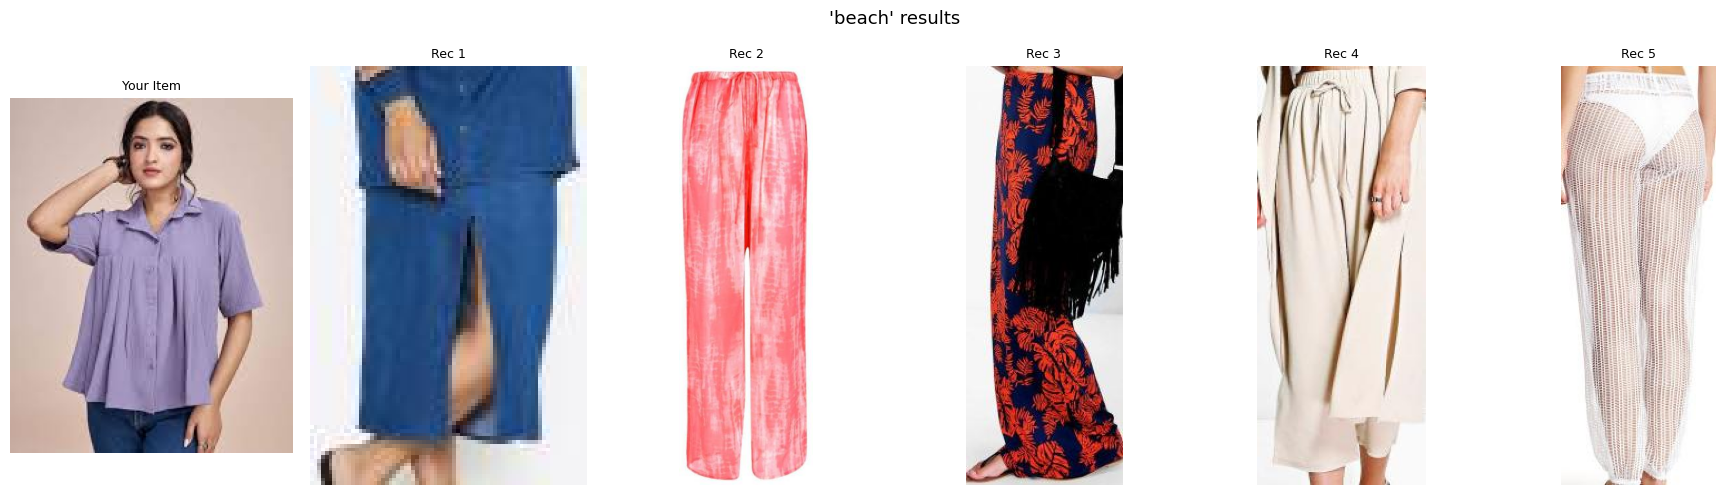


Rate each recommendation (1=👍, 0=👎, s=skip). For 👎 you can type a reason (Enter to skip):
    ❌ disliked saved
    ❌ disliked saved
    ❌ disliked saved
    ✅ liked saved
    ✅ liked saved

Feedback saved! 5 labeled examples so far.
Need at least 6 labeled examples to train (have 5). Keep rating!


In [146]:
from PIL import Image

# ── Upload your own image here ────────────────────────────────────────────
# Option 1 — local file
my_image = Image.open(r"C:\Users\shriy\OneDrive\Documents\ML-PROJECT-main\top6.jpg").convert("RGB")

# Option 2 — use any catalog image by index
# my_image = ds_f200k_filtered[500]["image"]

# ── Change these as you like ──────────────────────────────────────────────
mood         = "beach"   # e.g. "party night", "formal office", "beach day"
garment_type = "top"               # "top", "bottom", or "dress"

# ── Run ───────────────────────────────────────────────────────────────────
result = recommend_from_image_and_text(my_image, mood, garment_type=garment_type)
display_results(result, input_image=my_image, query_text=mood)

rate_recommendations(result)

In [147]:
import gradio as gr
from PIL import Image

_last_result = {}  # store last result for feedback

def run_recommendation(image, text, garment_type):
    global _last_result
    if image is not None and text.strip():
        result = recommend_from_image_and_text(image, text, garment_type=garment_type.lower())
    elif text.strip():
        result = recommend_from_text(text)
    else:
        return None, None, None, None, None, "No input provided."

    _last_result = result

    imgs = list(result.get("items", []))
    if not imgs and "dress_imgs" in result:
        imgs = list(result["dress_imgs"])
        for top_img, bot_img in result.get("outfit_imgs", []):
            imgs += [top_img, bot_img]
    imgs = imgs[:5]

    while len(imgs) < 5:
        imgs.append(None)
    return imgs[0], imgs[1], imgs[2], imgs[3], imgs[4], "Rate the recommendations below 👇"

def submit_feedback(r1, r2, r3):
    """Called when user submits ratings via radio buttons."""
    global _last_result
    if not _last_result:
        return "No recommendations to rate yet."

    log    = load_feedback_log()
    items  = _last_result.get("meta", pd.DataFrame())
    ratings = [r1, r2, r3]

    for i, (rating, (_, row)) in enumerate(zip(ratings, items.iterrows())):
        if rating in ("👍 Like", "👎 Dislike"):
            label = 1 if rating == "👍 Like" else 0
            feats = extract_feedback_features(
                query_text=_last_result.get("query_text", ""),
                query_is_patterned=_last_result.get("query_is_patterned", False),
                candidate_row=row,
                clip_similarity=row.get("clip_similarity", 0.0),
                compat_score=row.get("compat_score_raw", 0.0),
            )
            log.append({"features": feats, "label": label})

    save_feedback_log(log)

    # Auto-retrain every 5 examples
    msg = f"Feedback saved! {len(log)} total examples."
    if len(log) % 5 == 0:
        success = train_personalizer()
        msg += " ✅ Personalizer retrained." if success else " ⚠ Need more varied feedback."
    return msg


with gr.Blocks(title="Outfit Recommender") as demo:
    gr.Markdown("# 👗 Outfit Compatibility Recommender")

    with gr.Row():
        image_input   = gr.Image(type="pil", label="Upload garment (optional)")
        text_input    = gr.Textbox(label="Mood / occasion", placeholder="e.g. casual everyday")
        garment_input = gr.Dropdown(["top", "bottom", "dress"], label="Garment type", value="top")

    submit_btn = gr.Button("Get Recommendations", variant="primary")
    status_box = gr.Textbox(label="Status", interactive=False)

    with gr.Row():
        out1 = gr.Image(label="Rec 1")
        out2 = gr.Image(label="Rec 2")
        out3 = gr.Image(label="Rec 3")
        out4 = gr.Image(label="Rec 4")
        out5 = gr.Image(label="Rec 5")

    gr.Markdown("### Rate these recommendations")
    with gr.Row():
        fb1 = gr.Radio(["👍 Like", "👎 Dislike", "Skip"], label="Rec 1", value="Skip")
        fb2 = gr.Radio(["👍 Like", "👎 Dislike", "Skip"], label="Rec 2", value="Skip")
        fb3 = gr.Radio(["👍 Like", "👎 Dislike", "Skip"], label="Rec 3", value="Skip")

    feedback_btn = gr.Button("Submit Feedback")
    feedback_out = gr.Textbox(label="Feedback status", interactive=False)

    
    submit_btn.click(
        fn=run_recommendation,
        inputs=[image_input, text_input, garment_input],
        outputs=[out1, out2, out3, out4, out5, status_box]     
    )
    
    feedback_btn.click(
        fn=submit_feedback,
        inputs=[fb1, fb2, fb3],
        outputs=feedback_out
    )

demo.launch()

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.
